In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from train_rf_delay import get_client

In [5]:

df = get_client().query_df(
    "SELECT Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Step = 'curve' ORDER BY Train_Rows"
)

df

,Train_Rows,val_lift,train_lift
0,864107,1.464197,1.636116
1,1728215,1.479428,1.629697
2,3456430,1.481219,1.638586
3,6912859,1.482113,1.632090


In [6]:
plt.show()

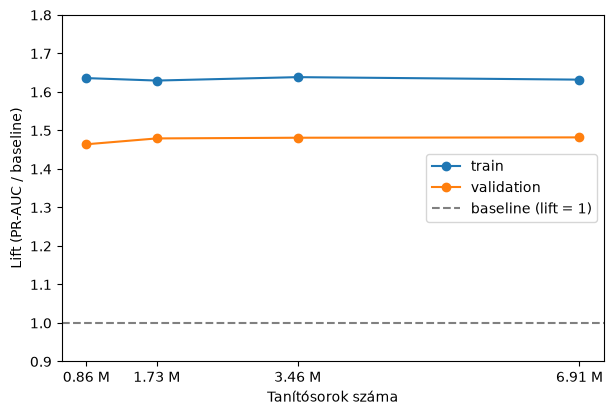

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(df["Train_Rows"], df["train_lift"], marker="o", label="train")
ax.plot(df["Train_Rows"], df["val_lift"], marker="o", label="validation")
ax.axhline(1.0, linestyle="--", color="gray", label="baseline (lift = 1)")

ax.set_xticks(df["Train_Rows"])
ax.set_xticklabels([f"{r / 1e6:.2f} M" for r in df["Train_Rows"]])


ax.set_ylim(0.9, 1.8)
ax.set_xlabel("Tanítósorok száma")
ax.set_ylabel("Lift (PR-AUC / baseline)")
ax.legend()

plt.show()

In [22]:
out = Path("../docs/figures/learning_curve_y1_4feat.png")
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=200, bbox_inches="tight")